# 511 keV Residual Analysis

This notebook applies the residual-analysis tools to the observed and fitted disk-scale histograms. It prepares a common mask and projections, then compares raw, Pearson, and fractional residual views


In [20]:
%load_ext autoreload
%autoreload 2

# Handle filesystem paths in a platform-independent way.
from pathlib import Path
import sys # Access the Python import path.

working_dir = Path.cwd()
repo_root = (
    working_dir.parent
    if working_dir.name == "notebooks"
    else working_dir
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Setup and imports

Set the workflow path and import the analysis, plotting, and histogram tools.


In [21]:
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals

from histpy import Histogram
import numpy as np
from IPython.display import display


## Load the observed and expected histograms

Both products are read from the saved disk-scale HDF5 file.


In [22]:
residual_dir = repo_root / "data" / "residual"
disk_scale_file = residual_dir / "03_511_imaging_residual_products.hdf5"

In [23]:
observed_disk_scale = Histogram.open(
    disk_scale_file,
    name="observed",
)

expected_disk_scale = Histogram.open(
    disk_scale_file,
    name="total_expectation",
)

## Initialize the analysis and inspect the mask

The analysis validates the histogram pair and reports bins excluded by its numerical-floor mask.


In [24]:
residual_analysis = ResidualAnalysis(
    observed_disk_scale,
    expected_disk_scale,
    expected_floor=1e-12,
)

In [25]:
residual_analysis.mask_report

{'total_bins': 184320,
 'valid_bins': np.int64(175104),
 'excluded_bins': np.int64(9216),
 'observed_counts_excluded': np.float64(0.0),
 'expected_floor': 1e-12,
 'minimum_expected': <Quantity 1.e-12>,
 'minimum_retained_expected': <Quantity 0.00156623>}

## Prepare the supported projections

The projection keys below are the names accepted by the residual and plotting methods.


In [26]:
# Build the projections and display their available names.
projected_data = residual_analysis.projected_data()
list(projected_data.keys())

['Phi_projection',
 'Chi_projection',
 'Psi_projection',
 'PsiChi_projection',
 'Phi_Chi_projection',
 'Phi_Psi_projection',
 'Phi_PsiChi_projection']

## Check projected counts and residual outputs

The following cell checks that each prepared projection preserves the total counts and that all three residual definitions return histograms with matching axes and shapes.

In [27]:
# Check count preservation and residual outputs for every projection.
residual_types = ("raw", "pearson", "fractional")
observed_total = float(np.sum(observed_disk_scale.contents))
expected_total = float(np.sum(expected_disk_scale.contents))

for projection_id, products in projected_data.items():
    np.testing.assert_allclose(
        np.sum(products["observed"].contents), observed_total
    )
    np.testing.assert_allclose(
        np.sum(products["expected"].contents), expected_total
    )
    for residual_type in residual_types:
        residual_hist = residual_analysis.residual_function(
            projection_id, residual_type
        )
        assert residual_hist.shape == products["observed"].shape
        assert list(residual_hist.axes.labels) == list(products["observed"].axes.labels)

print("All projections preserve counts and return compatible residual histograms.")

All projections preserve counts and return compatible residual histograms.


## Compact full-CDS residual summaries

Each table summarizes one residual type across the valid full-CDS bins. All three report the number of valid bins, mean, median, standard deviation, RMS, minimum, and maximum. The Pearson table also reports the fractions of bins with |R| > 2 and |R| > 3, Pearson chi-square, and Poisson deviance. The per-bin Poisson uncertainty σᵢ = √Mᵢ is shown in the observed-versus-expected count plots. These are descriptive summaries, not a calibrated goodness-of-fit test; no degrees of freedom or p-value is inferred.

In [28]:
# Display the compact full-CDS summary for raw residuals.
display(residual_analysis.statistics_table("raw"))

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual
0,175104,0.016627,-0.114364,1.091834,1.091961,-7.02206,12.370511


In [29]:
# Display the compact full-CDS summary for Pearson residuals.
display(residual_analysis.statistics_table("pearson"))

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,175104,0.006482,-0.095382,0.456881,0.456927,-1.626413,17.35212,0.401476,0.223867,36558.590854,25525.814956


In [30]:
# Display the compact full-CDS summary for fractional residuals.
display(residual_analysis.statistics_table("fractional"))

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual
0,175104,0.010447,-0.038624,2.107158,2.107184,-1.0,302.092783


## Check the one-dimensional Phi projection

First confirm the residual histogram has the expected axis and bin shape.


In [31]:
# Calculate the raw residual for the Phi projection.
phi_raw_residual = residual_analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

# Show the residual histogram's axis labels and shape.
print("Axes:", phi_raw_residual.axes.labels)
print("Shape:", phi_raw_residual.shape)

Axes: ['Phi']
Shape: (60,)


## One-dimensional Phi diagnostics

Compare the three residual definitions for the same projection. The Pearson histogram uses 1,000 fixed-fit Poisson realizations with a reproducible seed; its shaded band is the pointwise 95% interval across simulated histograms. This is a reference distribution, not a calibrated goodness-of-fit test.


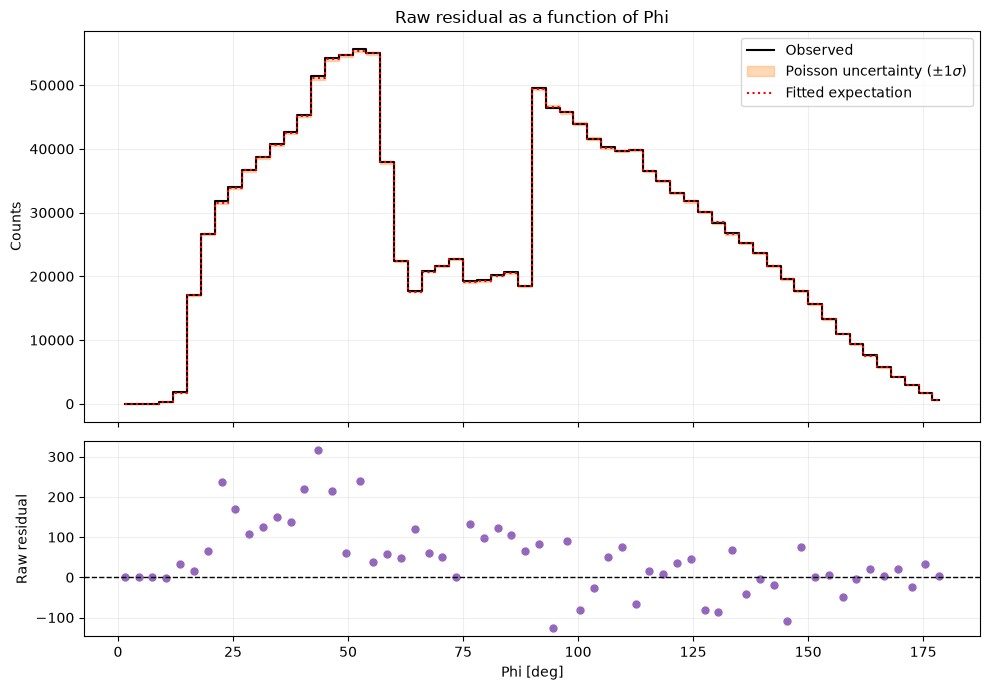

In [32]:
# Set the shared Pearson simulation options once; references are prepared on the first Pearson plot.
residual_plots = PlottingResiduals(
    residual_analysis,
    n_simulations=1000,
    random_seed=42,
    phi_bin_index=30,
)

# Plot observed and expected counts with the raw residual for Phi.
phi_raw_figure = residual_plots.plot(
    "Phi_projection",
    residual_type="raw",
)

In [ ]:
# Plot the Pearson residual diagnostic for the Phi projection.
phi_pearson_figure = residual_plots.plot(
    "Phi_projection",
    residual_type="pearson",
)

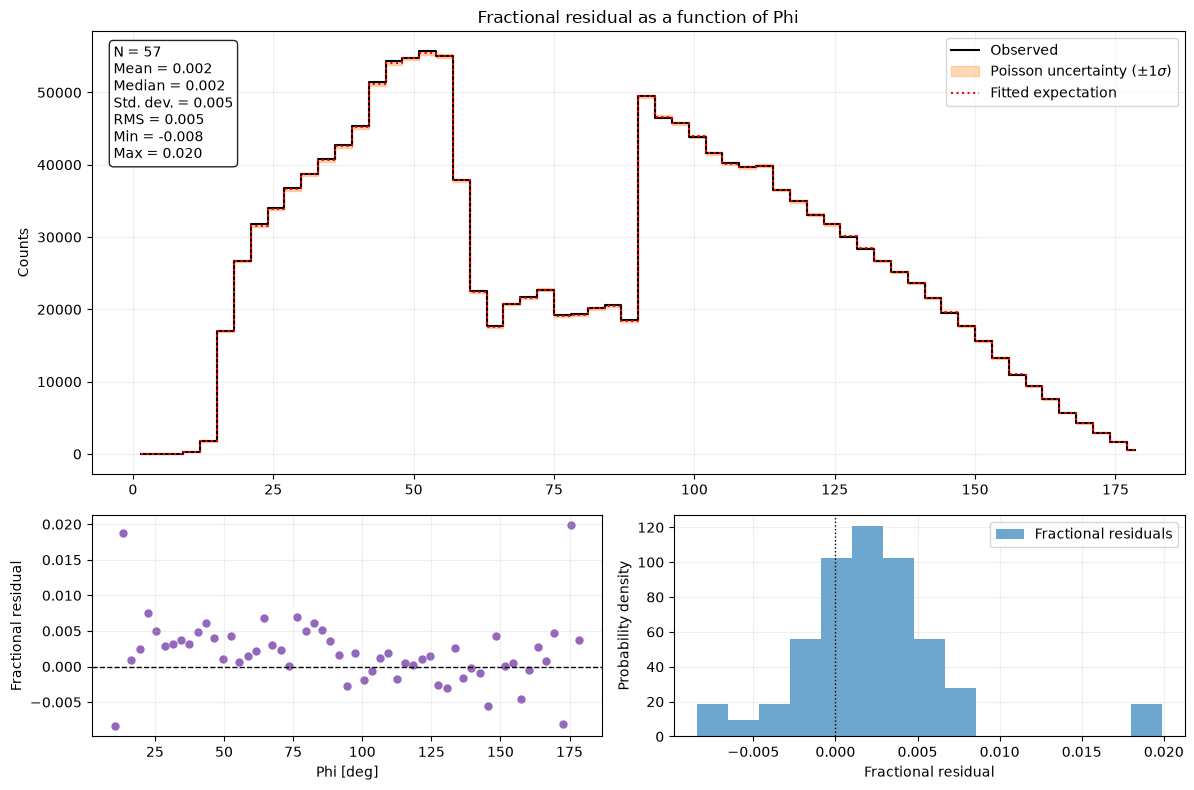

In [ ]:
# Plot the fractional residual diagnostic for the Phi projection.
phi_fractional_figure = residual_plots.plot(
    "Phi_projection",
    residual_type="fractional",
)

## One-dimensional Chi and Psi diagnostics

The same plotting method is used for the other two one-dimensional CDS coordinates and all three residual definitions.

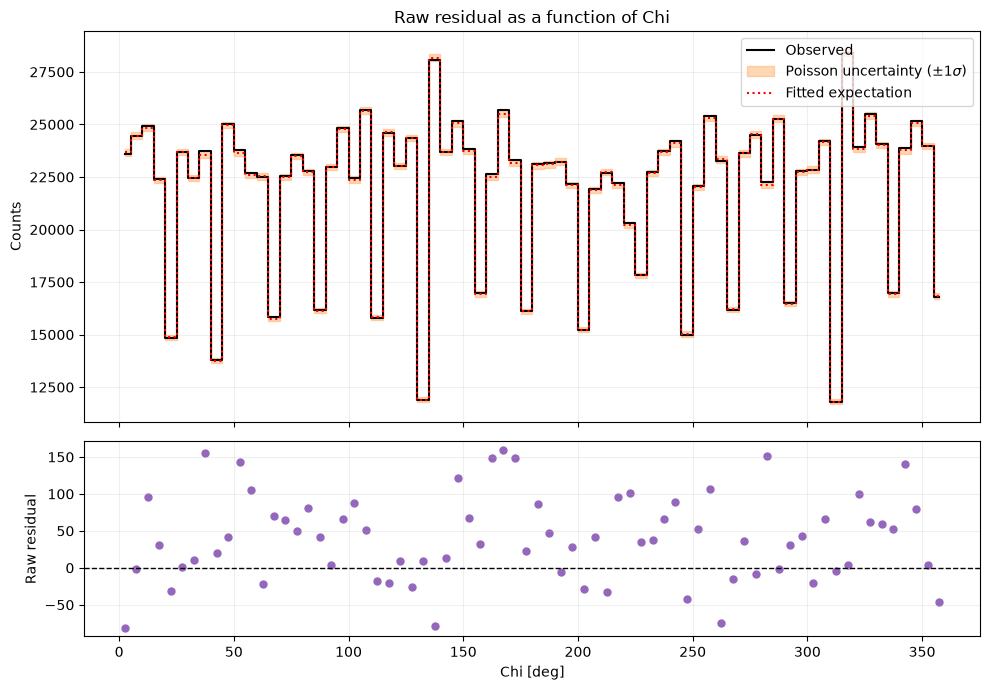

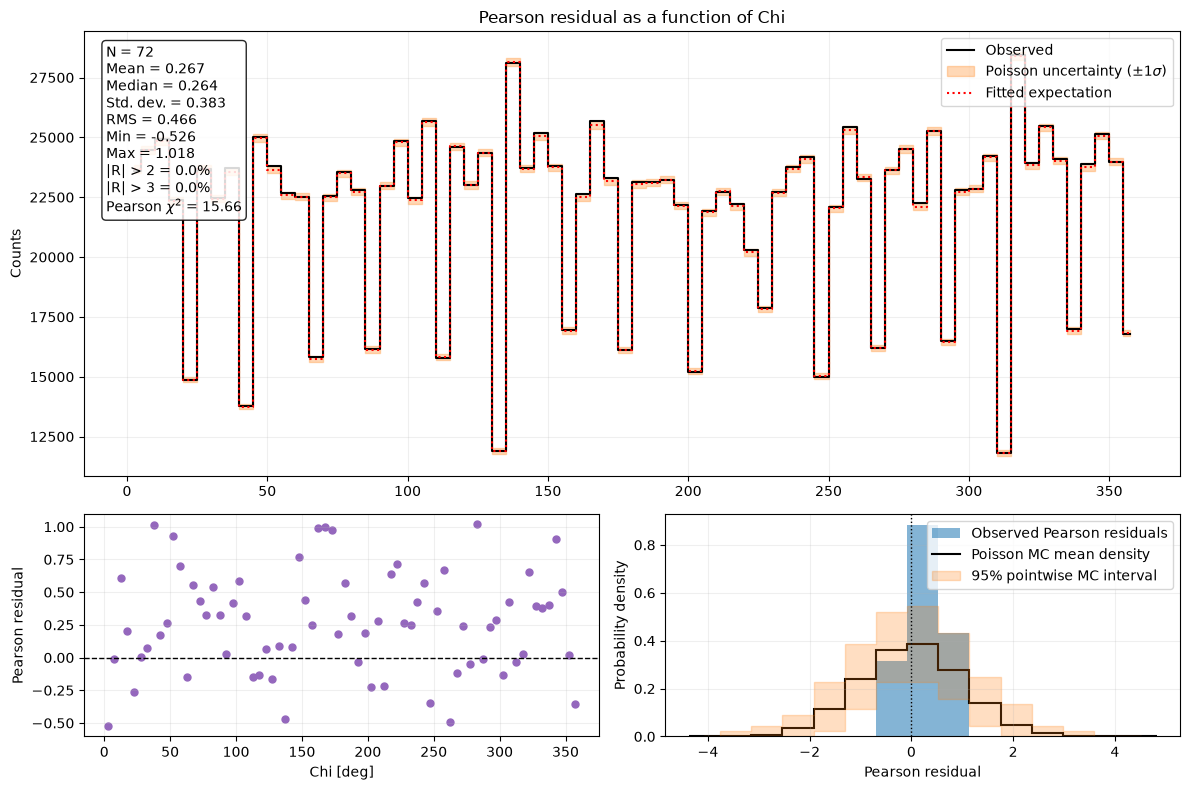

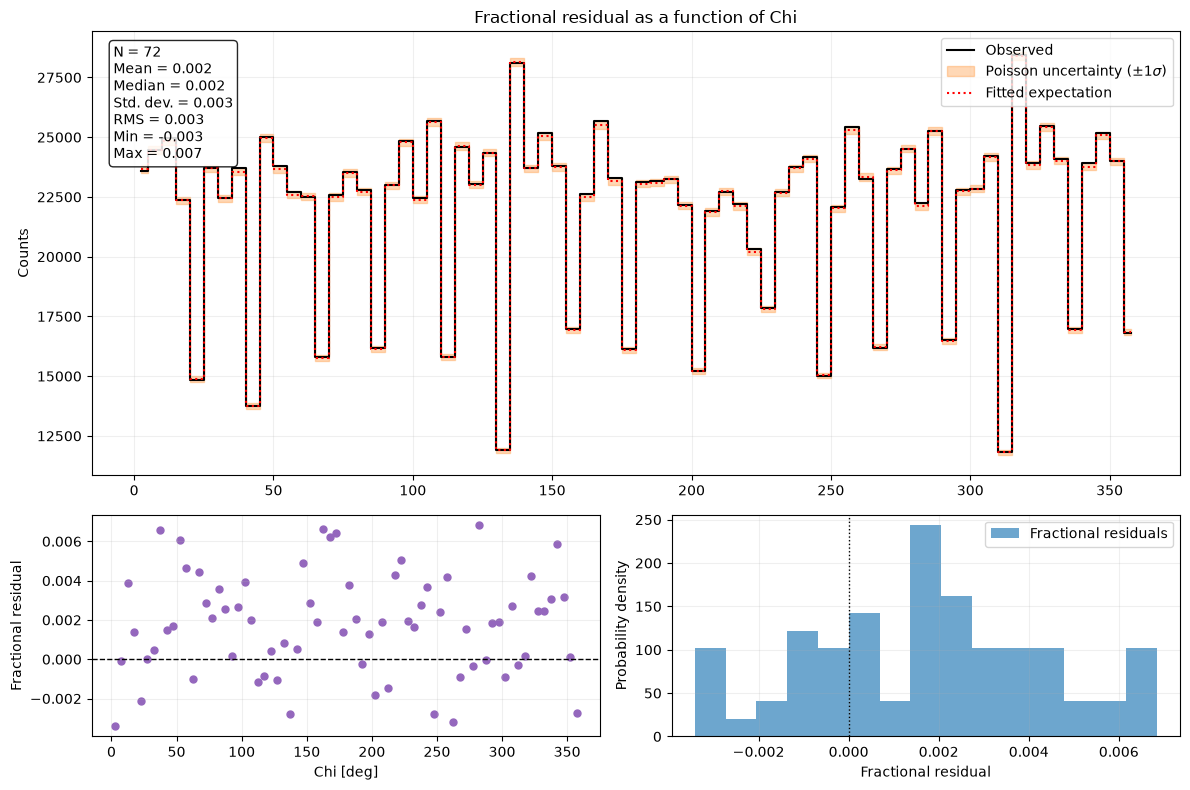

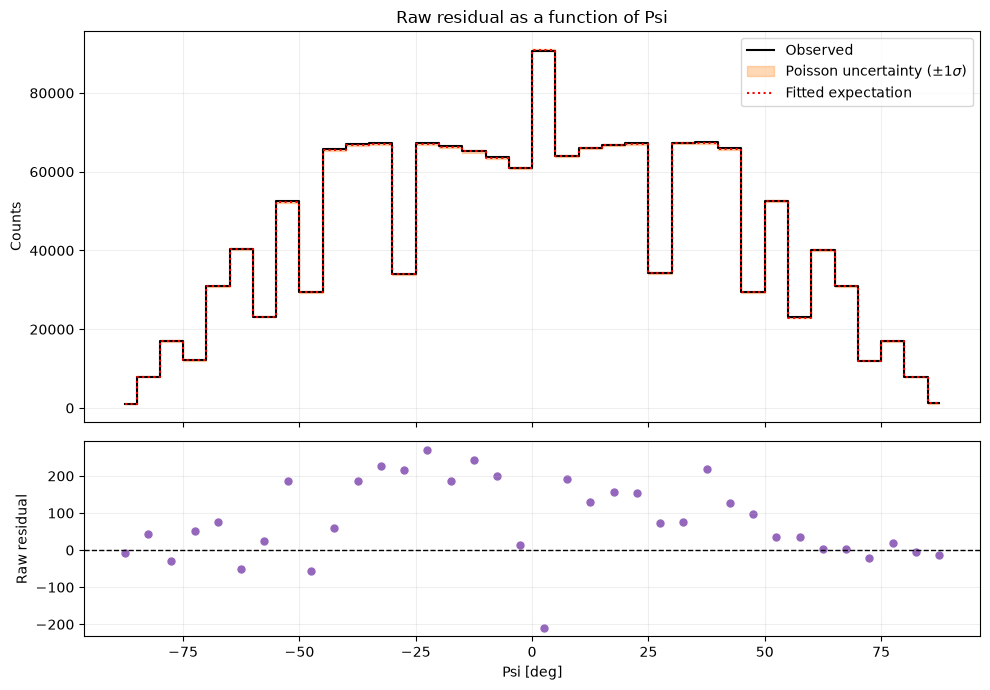

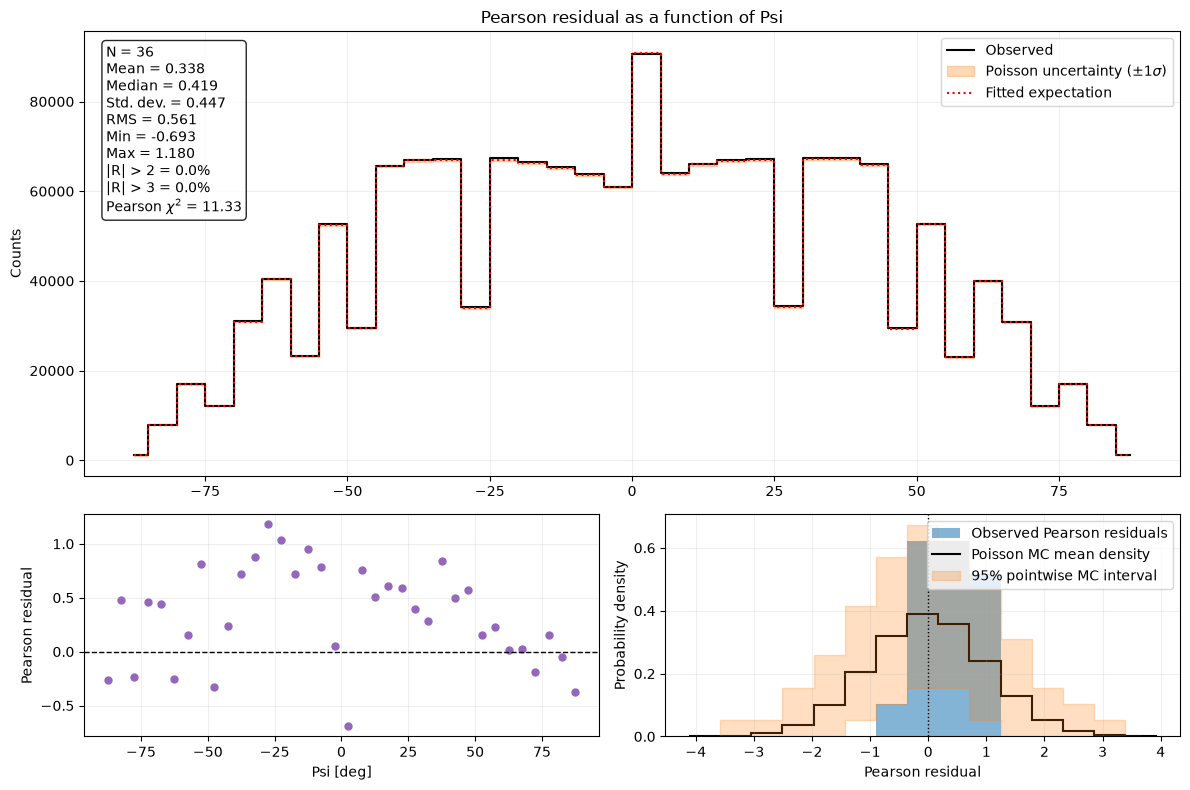

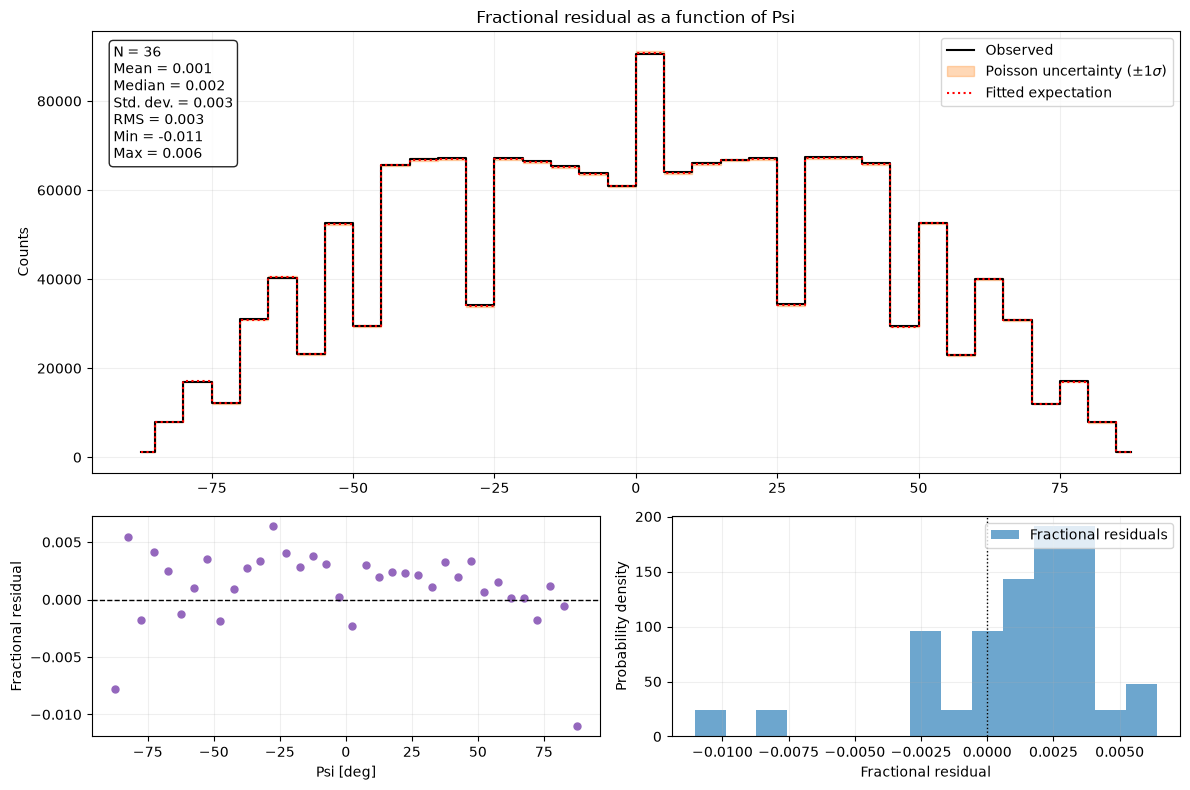

In [ ]:
# Plot raw, Pearson, and fractional residuals for Chi and Psi.
chi_psi_figures = {}
for projection_id in ("Chi_projection", "Psi_projection"):
    for residual_type in residual_types:
        chi_psi_figures[(projection_id, residual_type)] = residual_plots.plot(
            projection_id,
            residual_type=residual_type,
        )

## Rectangular Phi–Chi and Phi–Psi diagnostics

These calls display both paired maps.


/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:818: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


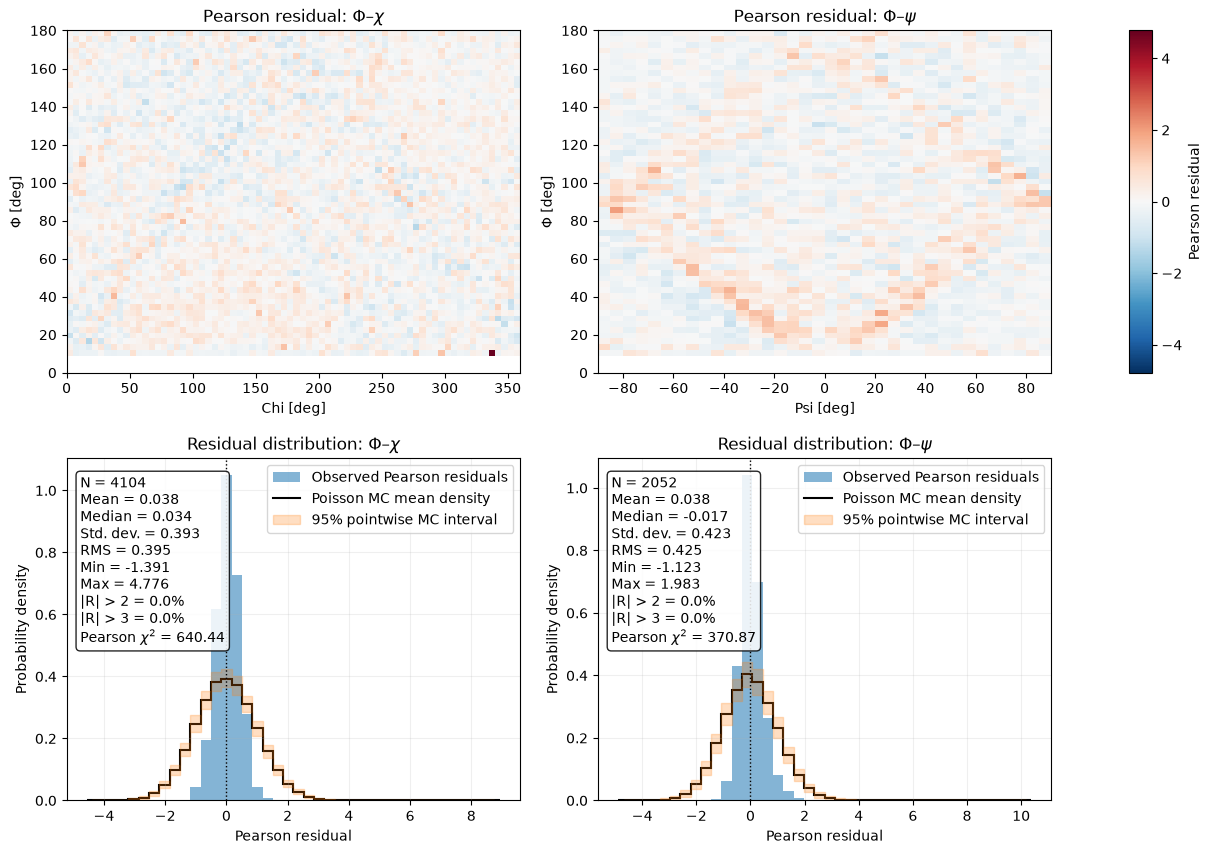

In [ ]:
# Plot the Pearson residual diagnostic for the Phi–Chi projection.
phi_chi_pearson_figure = residual_plots.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
)

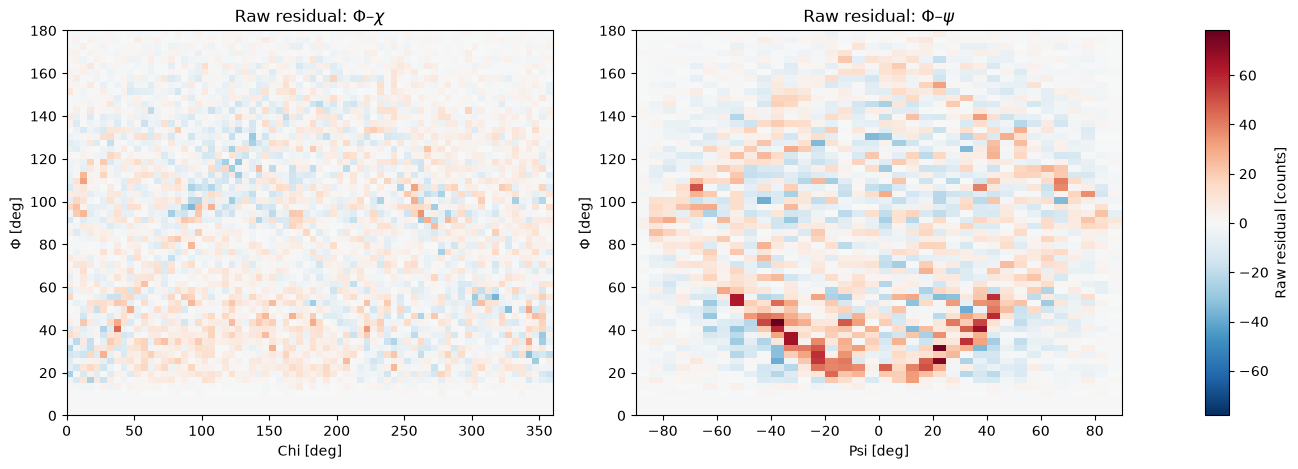

In [ ]:
# Plot raw residuals for the paired 2D projections.
phi_2d_raw_figure = residual_plots.plot(
    "Phi_Chi_projection",
    residual_type="raw",
)

## HEALPix PsiChi diagnostics

The first group is integrated over Phi; the second examines one selected Phi bin.


In [ ]:
# Plot Pearson residuals for the PsiChi projection integrated over Phi.
psichi_pearson_figure = residual_plots.plot(
    "PsiChi_projection",
    residual_type="pearson",
)

ValueError: phi_bin_index applies only to Phi_PsiChi_projection.

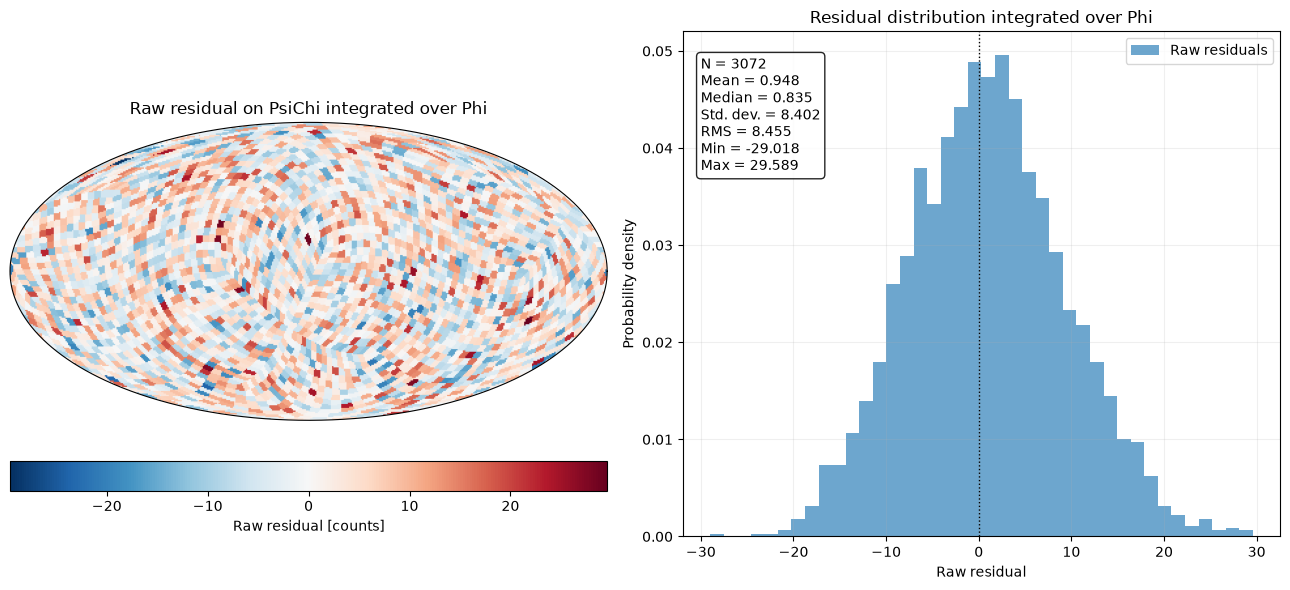

In [ ]:
# Plot raw residuals for the full PsiChi projection integrated over Phi.
psichi_raw_figure = residual_plots.plot(
    "PsiChi_projection",
    residual_type="raw",
)

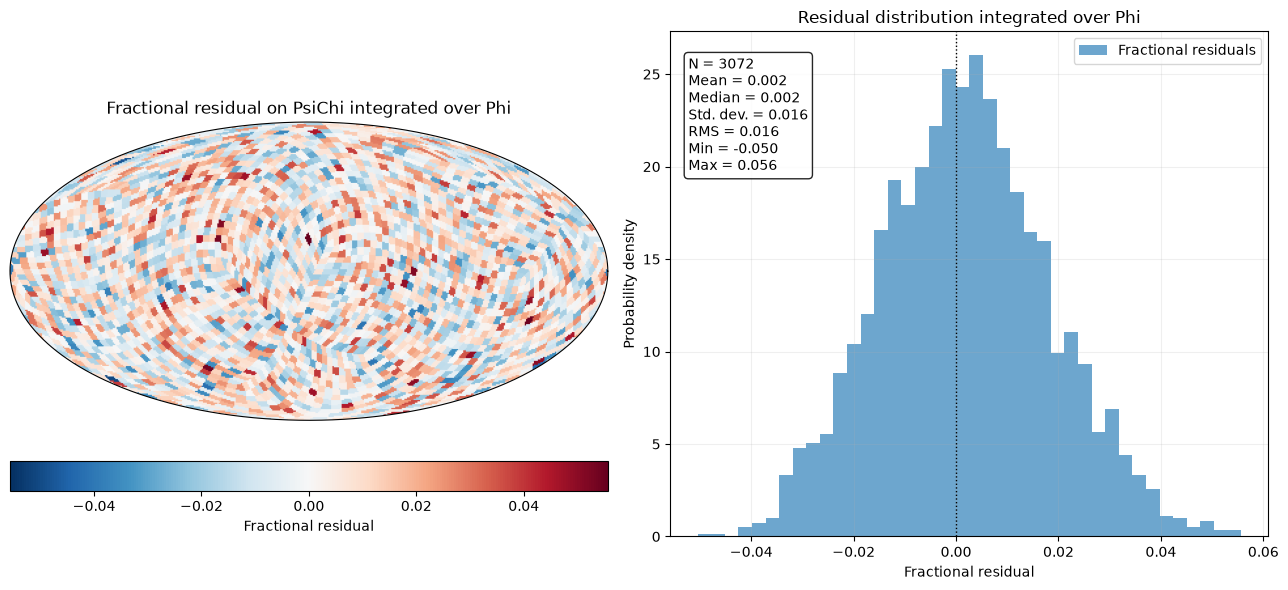

In [ ]:
# Plot fractional residuals for the full PsiChi projection integrated over Phi.
psichi_fractional_figure = residual_plots.plot(
    "PsiChi_projection",
    residual_type="fractional",
)


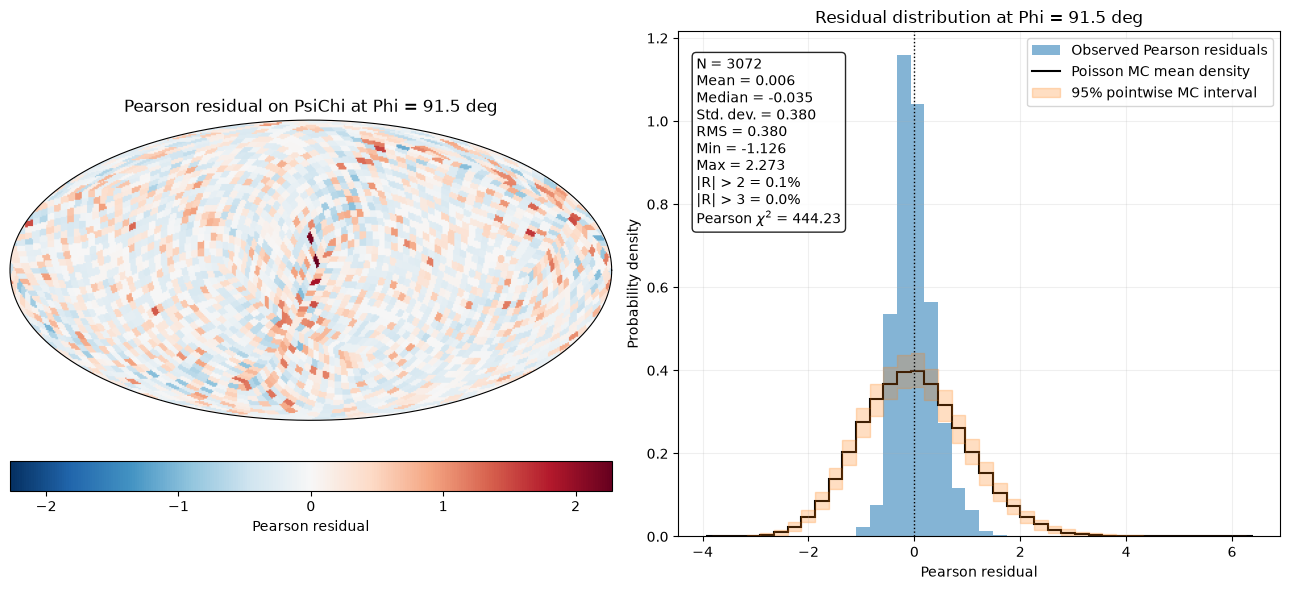

In [ ]:
# Plot the PsiChi map for the Phi bin centered near 91.5 degrees.
phi_slice_pearson_figure = residual_plots.plot(
    "Phi_PsiChi_projection",
    residual_type="pearson",
    phi_bin_index=30,
)

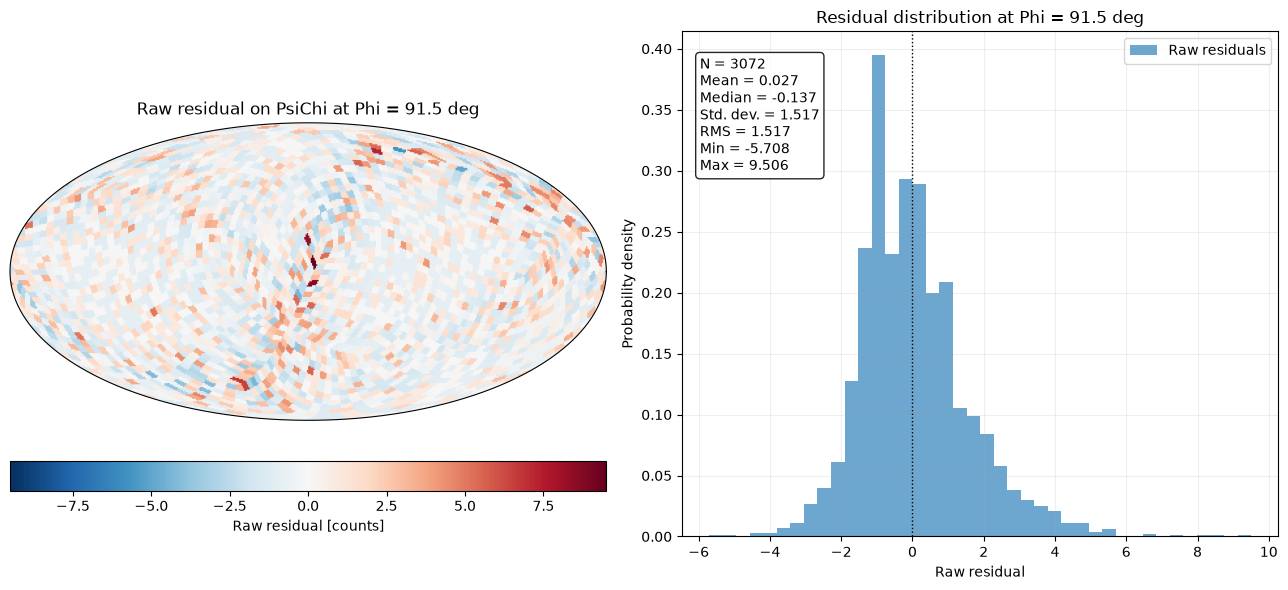

In [ ]:
# Plot raw residuals for the PsiChi map at the selected Phi bin.
phi_slice_raw_figure = residual_plots.plot(
    "Phi_PsiChi_projection",
    residual_type="raw",
    phi_bin_index=30,
)

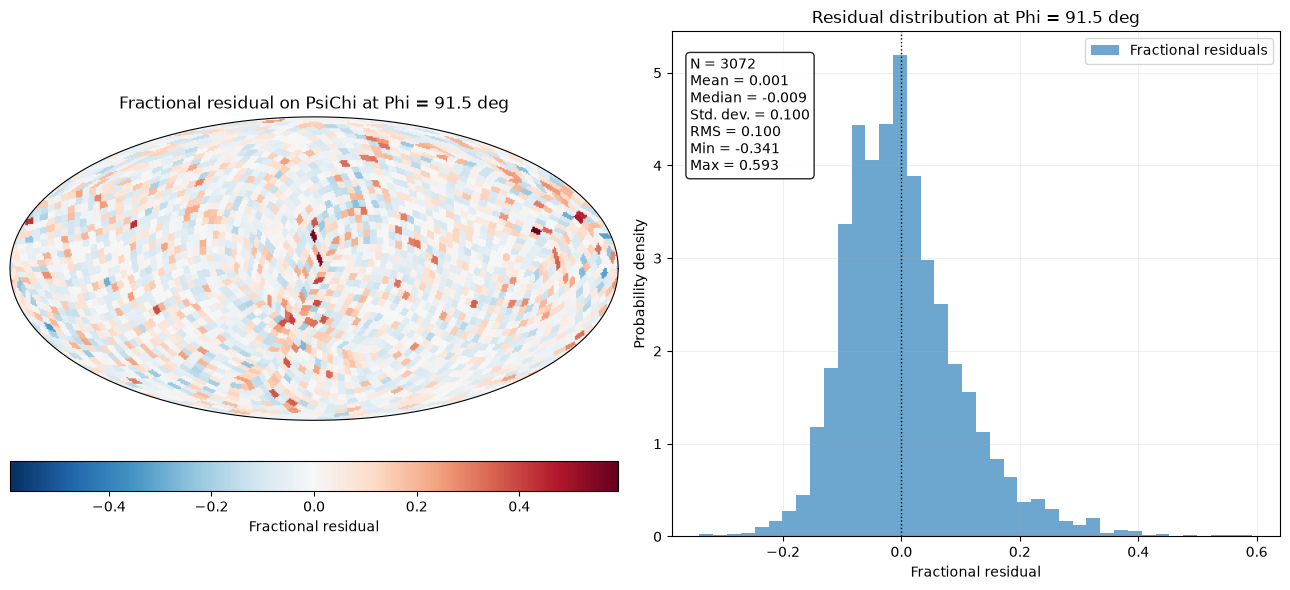

In [ ]:
# Plot fractional residuals for the PsiChi map at the selected Phi bin.
phi_slice_fractional_figure = residual_plots.plot(
    "Phi_PsiChi_projection",
    residual_type="fractional",
    phi_bin_index=30,
)

## Fractional 2D view: interpret the color scale with care

Fractional residuals divide the observed-minus-expected difference by the expectation. A low-expectation bin can therefore have a large relative residual even when its absolute count difference is small. In this dataset, the largest Phi–Chi value is at Phi = 10.5 deg and Chi = 337.5 deg: 3 observed counts versus an expectation of about 0.312, giving a fractional residual near 8.62. For the maps, the shared color range is set by the 99.5th percentile of absolute residuals; values beyond that range saturate at the colorbar limits, while the distributions and statistics retain their full values. The low-count outlier is not, by itself, evidence of a physical feature.


In [ ]:
# Find the Phi–Chi bin with the largest absolute fractional residual.

projection_products = residual_analysis.projected_data()["Phi_Chi_projection"]
fractional_hist = residual_analysis.residual_function(
    "Phi_Chi_projection",
    residual_type="fractional",
)
fractional_values = np.asarray(fractional_hist.contents, dtype=float)
bin_index = np.unravel_index(
    np.nanargmax(np.abs(fractional_values)),
    fractional_values.shape,
)

# Display the bin location and its observed, expected, and fractional values.
print("Bin index (Phi, Chi):", bin_index)
print("Phi center:", projection_products["observed"].axes["Phi"].centers[bin_index[0]])
print("Chi center:", projection_products["observed"].axes["Chi"].centers[bin_index[1]])
print("Observed:", projection_products["observed"].contents[bin_index])
print("Expected:", projection_products["expected"].contents[bin_index])
print("Fractional residual:", fractional_values[bin_index])

Bin index (Phi, Chi): (np.int64(3), np.int64(67))
Phi center: 10.5 deg
Chi center: 337.5 deg
Observed: 3.0
Expected: 0.31584720947159894
Fractional residual: 8.498263432559346


/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:733: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


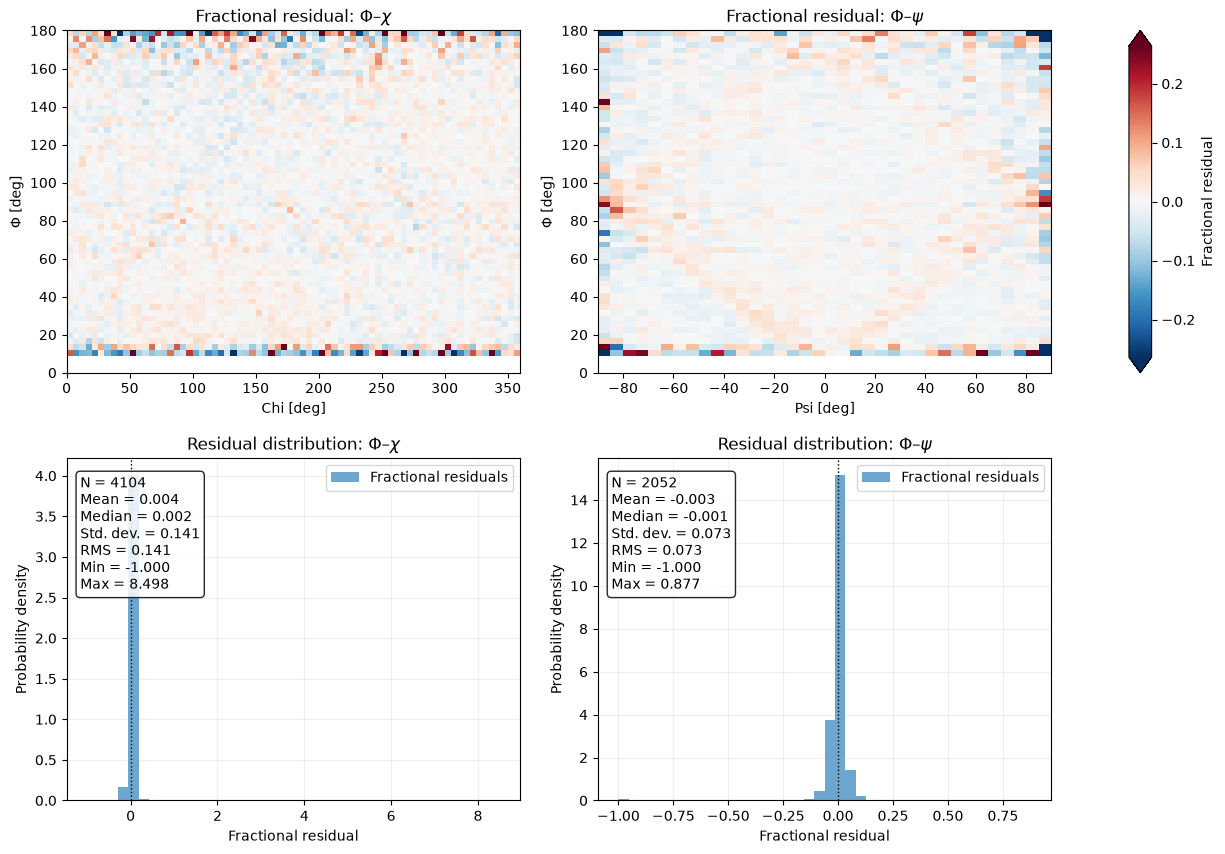

In [ ]:
# Plot fractional residual diagnostics for the paired 2D projections.
phi_2d_fractional_figure = residual_plots.plot(
    "Phi_Chi_projection",
    residual_type="fractional",
)